In [4]:
import matplotlib
import matplotlib.pyplot as plt
import pickle
import numpy as np
import os,sys
sys.path.append('..')
from H2_6_31G_8Qbit import H2_6_31G_8Qbit

In [5]:
with open('./data/26-10-26-06-30_history_K2_frozen6_deflation_MatrixFree_Pure.pkl', 'rb') as f:
    data = pickle.load(f)

molecule = H2_6_31G_8Qbit(K=10)

In [6]:
molecule.E_fcis

array([-1.05434745, -0.95790573, -0.66895227, -0.55140192, -0.02803278,
       -0.01450343, -0.00518297,  0.02397075,  0.2343239 ,  0.25720575,
        0.49958128,  0.50024484])

In [7]:
lam_history = data['lam']
lam_arr = np.asarray(lam_history)
lam_arr = lam_arr[-1,0]
lam_arr

np.float64(-0.005393558842849135)

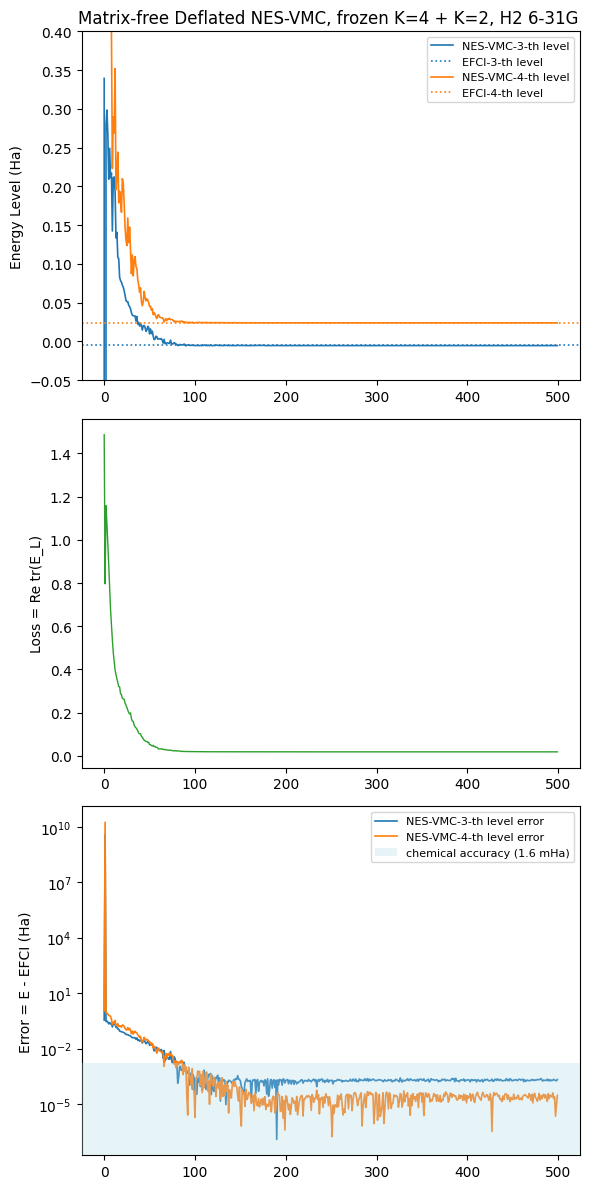

In [9]:
steps_history = data['steps']
lam_history = data['lam']
loss_history = data['loss']
diag_history = data['diag']
elapsed_history = data['elapsed_s']
K=2
N_ITER = len(steps_history)
steps_arr = np.asarray(steps_history)
lam_arr = np.asarray(lam_history)
loss_arr = np.asarray(loss_history)
elapsed = np.asarray(elapsed_history)
diag = {k: np.asarray([d[k] for d in diag_history]) for k in diag_history[0]}

# ========== 配色定义：K个能级一一对应 ==========
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#bcbd22", "#17becf"]  # 第0条、第1条能级的固定颜色
fci_targets = molecule.E_fcis[6:6+K]

fig, axs = plt.subplots(3, 1, figsize=(6, 12))

# 子图0：λ_hat + FCI基准线，同能级同色
for k in range(K):
    axs[0].plot(steps_arr, lam_arr[:,k], lw=1.2, color=colors[k], label=f"NES-VMC-{3+k}-th level")
    axs[0].axhline(fci_targets[k], lw=1.2, linestyle=':', color=colors[k], label=f"EFCI-{3+k}-th level")
axs[0].set_ylabel("Energy Level (Ha)")
axs[0].set_title(f"Matrix-free Deflated NES-VMC, frozen K=4 + K={K}, H2 6-31G ")
axs[0].xaxis.set_major_formatter('{x:.0f}')
axs[0].set_ylim(-0.05,0.4)
axs[0].legend(fontsize=8)

# 子图1：Loss
m = np.isfinite(loss_arr)
axs[1].plot(steps_arr[m], loss_arr[m], lw=1.0, color="#2ca02c")
axs[1].set_ylabel("Loss = Re tr(E_L)")
axs[1].xaxis.set_major_formatter('{x:.0f}')

# 子图2：误差曲线，同能级复用上面的颜色
for k in range(K):
    error_k = np.abs(lam_arr[:,k] - fci_targets[k])
    axs[2].plot(steps_arr, error_k, lw=1.2, color=colors[k], label=f"NES-VMC-{3+k}-th level error")

axs[2].set_ylabel(f"Error = E - EFCI (Ha)")
axs[2].set_yscale("log")
axs[2].axhspan(0, 0.0016, facecolor="lightblue", alpha=0.3, zorder=10, label="chemical accuracy (1.6 mHa)")
axs[2].legend(fontsize=8)

fig.tight_layout()
